# Compare classifier ensembles

This notebook loads the best ConvNeXt Tiny, ViT Tiny, Swin Tiny, and EfficientNetV2-S checkpoints selected by their training notebooks. It compares hard voting, equal probability voting, globally weighted probability voting, and model-by-class weighted probability voting. Weights are derived only from validation data. Complete validation and test results are saved for every ensemble method, while the best validation macro-F1 method is still recorded as the validation-selected method. Each model retains its own saved context radius, input size, and training-derived normalization statistics.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").exists()
    or (PROJECT_ROOT / "Data").exists()
    or (PROJECT_ROOT / "pmaciag-volume-beach").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if (PROJECT_ROOT / "pmaciag-volume-beach").exists():
    PROJECT_ROOT = PROJECT_ROOT / "pmaciag-volume-beach"
if not ((PROJECT_ROOT / "Source").exists() or (PROJECT_ROOT / "Data").exists()):
    raise RuntimeError("Could not locate pmaciag-volume-beach project directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import read_class_name_mapping, read_split_csv
from Source.ensemble import (
    average_probabilities,
    class_weighted_average_probabilities,
    hard_voting_predictions,
    load_model_artifact,
    macro_f1_weights,
    per_class_f1_weights,
    predict_artifact_on_split,
    validate_artifact_compatibility,
    weighted_average_probabilities,
)
from Source.training import classification_metrics, get_device

In [2]:
CELL_DATA_ROOT = PROJECT_ROOT / "Data" / "Raw" / "beach_all"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "Classes.xlsx"
PREPROCESSED_DIR = PROJECT_ROOT / "Data" / "Preprocessed"
OUTPUT_DIR = PROJECT_ROOT / "Results" / "ensemble"

VALIDATION_SPLIT = PREPROCESSED_DIR / "validation_split.csv"
TEST_SPLIT = PREPROCESSED_DIR / "test_split.csv"

MODEL_RESULT_DIRS = {
    "convnext_tiny": PROJECT_ROOT / "Results" / "convnext_tiny",
    "vit_tiny": PROJECT_ROOT / "Results" / "vit_tiny",
    "swin_tiny": PROJECT_ROOT / "Results" / "swin_tiny",
    "efficientnetv2_s": PROJECT_ROOT / "Results" / "efficientnetv2_s",
}

BATCH_SIZE = 32
NUM_WORKERS = 8

print(f"Project root:   {PROJECT_ROOT}", flush=True)
print(f"Cell data root: {CELL_DATA_ROOT}", flush=True)
print(f"Output dir:     {OUTPUT_DIR}", flush=True)

Project root:   /workspace/pmaciag-volume-beach


Cell data root: /workspace/pmaciag-volume-beach/Data/Raw/beach_all


Output dir:     /workspace/pmaciag-volume-beach/Results/ensemble


In [3]:
print("Loading splits and best-model artifacts...", flush=True)
if not CELL_DATA_ROOT.exists():
    raise FileNotFoundError(f"Cell data directory not found: {CELL_DATA_ROOT}")

validation_df = read_split_csv(VALIDATION_SPLIT)
test_df = read_split_csv(TEST_SPLIT)
artifacts = [
    load_model_artifact(name, result_dir)
    for name, result_dir in MODEL_RESULT_DIRS.items()
]
validate_artifact_compatibility(artifacts)

reference_metadata = artifacts[0].metadata
class_to_idx = {
    str(code): int(index)
    for code, index in reference_metadata["class_to_idx"].items()
}
idx_to_class_code = {
    int(index): str(code)
    for index, code in reference_metadata["idx_to_class_code"].items()
}
expected_classes = set(class_to_idx)
for split_name, split_df in [("validation", validation_df), ("test", test_df)]:
    split_classes = set(split_df["class"].astype(str))
    if not split_classes.issubset(expected_classes):
        raise ValueError(
            f"{split_name} split contains classes absent from model metadata: "
            f"{sorted(split_classes - expected_classes)}"
        )

class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, expected_classes)
idx_to_class_name = {
    index: f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for index, code in idx_to_class_code.items()
}

artifact_table = pd.DataFrame(
    [
        {
            "model": artifact.name,
            "architecture": artifact.metadata.get("model_name", artifact.metadata["model_type"]),
            "context_radius": artifact.metadata["context_radius"],
            "image_size": artifact.metadata["image_size"],
            "checkpoint": str(artifact.checkpoint_path),
        }
        for artifact in artifacts
    ]
)
print(f"Validation rows: {len(validation_df):,}", flush=True)
print(f"Test rows:       {len(test_df):,}", flush=True)
display(artifact_table)

Loading splits and best-model artifacts...


Validation rows: 1,218


Test rows:       1,219


,model,architecture,context_radius,image_size,checkpoint
0,convnext_tiny,convnext_tiny,2,224,/workspace/pmaciag-volume-beach/Results/convne...
1,vit_tiny,vit_tiny_patch16_224,2,224,/workspace/pmaciag-volume-beach/Results/vit_ti...
2,swin_tiny,swin_tiny_patch4_window7_224,2,224,/workspace/pmaciag-volume-beach/Results/swin_t...
3,efficientnetv2_s,tf_efficientnetv2_s,1,224,/workspace/pmaciag-volume-beach/Results/effici...


In [4]:
def metric_summary(method_name, y_true, y_pred):
    return {
        "method": method_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }


print("Generating validation probabilities for ensemble search...", flush=True)
device = get_device()
validation_probabilities = {}
validation_y_true = None

for artifact in artifacts:
    print(f"Validation inference: {artifact.name}", flush=True)
    current_y_true, current_probabilities = predict_artifact_on_split(
        artifact,
        validation_df,
        CELL_DATA_ROOT,
        device=device,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
    )
    if validation_y_true is None:
        validation_y_true = current_y_true
    elif not np.array_equal(validation_y_true, current_y_true):
        raise RuntimeError(f"Validation target order differs for {artifact.name}.")
    validation_probabilities[artifact.name] = current_probabilities

validation_model_macro_f1, global_model_weights = macro_f1_weights(
    validation_y_true,
    validation_probabilities,
)
validation_class_f1, model_class_weights = per_class_f1_weights(
    validation_y_true,
    validation_probabilities,
)

hard_predictions, hard_vote_probabilities = hard_voting_predictions(
    validation_probabilities
)
validation_candidate_probabilities = {
    "hard_voting": hard_vote_probabilities,
    "probability_voting": average_probabilities(validation_probabilities),
    "weighted_probability_per_model": weighted_average_probabilities(
        validation_probabilities,
        global_model_weights,
    ),
    "weighted_probability_per_model_class": class_weighted_average_probabilities(
        validation_probabilities,
        model_class_weights,
    ),
}
validation_candidate_predictions = {
    name: probabilities.argmax(axis=1)
    for name, probabilities in validation_candidate_probabilities.items()
}
validation_candidate_predictions["hard_voting"] = hard_predictions

ensemble_method_order = [
    "hard_voting",
    "probability_voting",
    "weighted_probability_per_model",
    "weighted_probability_per_model_class",
]
validation_search_df = pd.DataFrame(
    [
        metric_summary(
            method,
            validation_y_true,
            validation_candidate_predictions[method],
        )
        for method in ensemble_method_order
    ]
)
best_ensemble_method = max(
    ensemble_method_order,
    key=lambda method: float(
        validation_search_df.loc[
            validation_search_df["method"] == method,
            "macro_f1",
        ].iloc[0]
    ),
)
validation_search_df["selected"] = validation_search_df["method"].eq(best_ensemble_method)
validation_ensemble_probability = validation_candidate_probabilities[best_ensemble_method]
validation_ensemble_pred = validation_candidate_predictions[best_ensemble_method]

global_weight_table = pd.DataFrame(
    [
        {
            "model": name,
            "validation_macro_f1": validation_model_macro_f1[name],
            "ensemble_weight": global_model_weights[name],
        }
        for name in validation_probabilities
    ]
).sort_values("validation_macro_f1", ascending=False)

class_weight_table = pd.DataFrame(
    [
        {
            "model": name,
            "class_index": class_index,
            "class_code": idx_to_class_code[class_index],
            "class_name": class_name_by_code.get(
                idx_to_class_code[class_index],
                f"class_{idx_to_class_code[class_index]}",
            ),
            "validation_class_f1": validation_class_f1[name][class_index],
            "ensemble_weight": model_class_weights[name][class_index],
        }
        for class_index in range(len(idx_to_class_code))
        for name in validation_probabilities
    ]
).sort_values(["class_index", "ensemble_weight"], ascending=[True, False])

validation_reports = {}
validation_confusions = {}
for method in ensemble_method_order:
    report, confusion = classification_metrics(
        validation_y_true,
        validation_candidate_predictions[method],
        idx_to_class_name,
    )
    validation_reports[method] = report
    validation_confusions[method] = confusion

print(f"Selected ensemble method: {best_ensemble_method}", flush=True)
display(validation_search_df.sort_values("macro_f1", ascending=False))
display(global_weight_table)
display(class_weight_table)

Generating validation probabilities for ensemble search...


Validation inference: convnext_tiny


Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Validation inference: vit_tiny


Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

...

Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Selected ensemble method: probability_voting


,method,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,selected
1,probability_voting,0.941708,0.942501,0.957762,0.949825,0.941689,True
2,weighted_probability_per_model,0.941708,0.942501,0.957762,0.949825,0.941689,False
3,weighted_probability_per_model_class,0.941708,0.942501,0.957762,0.949825,0.941689,False
0,hard_voting,0.940887,0.941037,0.957482,0.948900,0.940871,False


,model,validation_macro_f1,ensemble_weight
2,swin_tiny,0.945580,0.254450
1,vit_tiny,0.930510,0.250395
0,convnext_tiny,0.928990,0.249986
3,efficientnetv2_s,0.911096,0.245170


,model,class_index,class_code,class_name,validation_class_f1,ensemble_weight
0,convnext_tiny,0,0,Snow,0.972973,0.261913
2,swin_tiny,0,0,Snow,0.972973,0.261913
3,efficientnetv2_s,0,0,Snow,0.918919,0.247363
1,vit_tiny,0,0,Snow,0.850000,0.228810
5,vit_tiny,1,1,Dry sediment,0.936170,0.256975
6,swin_tiny,1,1,Dry sediment,0.919942,0.252520
4,convnext_tiny,1,1,Dry sediment,0.902655,0.247775
7,efficientnetv2_s,1,1,Dry sediment,0.884273,0.242729
9,vit_tiny,2,2,Wet sediment,0.905312,0.257955
10,swin_tiny,2,2,Wet sediment,0.895455,0.255146


In [5]:
print("Ensemble definitions are frozen. Generating test predictions for all methods...", flush=True)
test_probabilities = {}
test_y_true = None

for artifact in artifacts:
    print(f"Test inference: {artifact.name}", flush=True)
    current_y_true, current_probabilities = predict_artifact_on_split(
        artifact,
        test_df,
        CELL_DATA_ROOT,
        device=device,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
    )
    if test_y_true is None:
        test_y_true = current_y_true
    elif not np.array_equal(test_y_true, current_y_true):
        raise RuntimeError(f"Test target order differs for {artifact.name}.")
    test_probabilities[artifact.name] = current_probabilities

test_hard_predictions, test_hard_vote_probabilities = hard_voting_predictions(
    test_probabilities
)
test_candidate_probabilities = {
    "hard_voting": test_hard_vote_probabilities,
    "probability_voting": average_probabilities(test_probabilities),
    "weighted_probability_per_model": weighted_average_probabilities(
        test_probabilities,
        global_model_weights,
    ),
    "weighted_probability_per_model_class": class_weighted_average_probabilities(
        test_probabilities,
        model_class_weights,
    ),
}
test_candidate_predictions = {
    name: probabilities.argmax(axis=1)
    for name, probabilities in test_candidate_probabilities.items()
}
test_candidate_predictions["hard_voting"] = test_hard_predictions

test_ensemble_probability = test_candidate_probabilities[best_ensemble_method]
test_ensemble_pred = test_candidate_predictions[best_ensemble_method]
print("Finished all test inference and ensemble predictions.", flush=True)

Ensemble definitions are frozen. Generating test predictions for all methods...


Test inference: convnext_tiny


Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Test inference: vit_tiny


Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Test inference: swin_tiny


Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Test inference: efficientnetv2_s


Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Finished all test inference and ensemble predictions.


In [6]:
print("Computing and saving individual-model and all-ensemble metrics...", flush=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
comparison_rows = []
individual_predictions = {}

for name, probabilities in test_probabilities.items():
    predictions = probabilities.argmax(axis=1)
    individual_predictions[name] = predictions
    row = metric_summary(name, test_y_true, predictions)
    row["model"] = row.pop("method")
    row["result_type"] = "individual_model"
    comparison_rows.append(row)
    model_report, model_confusion = classification_metrics(
        test_y_true,
        predictions,
        idx_to_class_name,
    )
    model_report.to_csv(OUTPUT_DIR / f"test_{name}_classification_report.csv")
    model_confusion.to_csv(OUTPUT_DIR / f"test_{name}_confusion_matrix.csv")

test_ensemble_reports = {}
test_ensemble_confusions = {}
for method in ensemble_method_order:
    predictions = test_candidate_predictions[method]
    row = metric_summary(f"ensemble_{method}", test_y_true, predictions)
    row["model"] = row.pop("method")
    row["result_type"] = "ensemble"
    row["validation_selected"] = method == best_ensemble_method
    comparison_rows.append(row)
    report, confusion = classification_metrics(
        test_y_true,
        predictions,
        idx_to_class_name,
    )
    test_ensemble_reports[method] = report
    test_ensemble_confusions[method] = confusion
    report.to_csv(OUTPUT_DIR / f"test_{method}_classification_report.csv")
    confusion.to_csv(OUTPUT_DIR / f"test_{method}_confusion_matrix.csv")

comparison_df = pd.DataFrame(comparison_rows).sort_values("macro_f1", ascending=False)
ensemble_report = test_ensemble_reports[best_ensemble_method]
ensemble_confusion = test_ensemble_confusions[best_ensemble_method]

validation_search_df.to_csv(OUTPUT_DIR / "validation_ensemble_search.csv", index=False)
global_weight_table.to_csv(OUTPUT_DIR / "validation_model_weights.csv", index=False)
class_weight_table.to_csv(OUTPUT_DIR / "validation_model_class_weights.csv", index=False)
for method in ensemble_method_order:
    validation_reports[method].to_csv(
        OUTPUT_DIR / f"validation_{method}_classification_report.csv"
    )
    validation_confusions[method].to_csv(
        OUTPUT_DIR / f"validation_{method}_confusion_matrix.csv"
    )

validation_reports[best_ensemble_method].to_csv(
    OUTPUT_DIR / "validation_ensemble_classification_report.csv"
)
validation_confusions[best_ensemble_method].to_csv(
    OUTPUT_DIR / "validation_ensemble_confusion_matrix.csv"
)
comparison_df.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)
ensemble_report.to_csv(OUTPUT_DIR / "test_ensemble_classification_report.csv")
ensemble_confusion.to_csv(OUTPUT_DIR / "test_ensemble_confusion_matrix.csv")

display(comparison_df)
ensemble_report

Computing and saving individual-model and all-ensemble metrics...


,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,model,result_type,validation_selected
5,0.953240,0.964162,0.967082,0.965333,0.953144,ensemble_probability_voting,ensemble,True
6,0.953240,0.964162,0.967082,0.965333,0.953144,ensemble_weighted_probability_per_model,ensemble,False
7,0.952420,0.963723,0.966082,0.964566,0.952312,ensemble_weighted_probability_per_model_class,ensemble,False
4,0.948318,0.959479,0.963106,0.960940,0.948159,ensemble_hard_voting,ensemble,False
1,0.914684,0.920188,0.937278,0.927849,0.914342,vit_tiny,individual_model,NaN
2,0.930271,0.907088,0.955392,0.927738,0.930277,swin_tiny,individual_model,NaN
3,0.903199,0.917651,0.925933,0.921193,0.903355,efficientnetv2_s,individual_model,NaN
0,0.906481,0.912661,0.929111,0.919375,0.905939,convnext_tiny,individual_model,NaN


,precision,recall,f1-score,support
0: Snow,1.000000,1.000000,1.000000,17.00000
1: Dry sediment,0.962751,0.938547,0.950495,358.00000
2: Wet sediment,0.918182,0.930876,0.924485,217.00000
3: Water,0.978261,0.900000,0.937500,100.00000
4: Bedrock,0.944954,0.971698,0.958140,106.00000
5: Boulder,0.979381,0.979381,0.979381,97.00000
6: Driftwood,0.962963,0.975000,0.968944,80.00000
7: Algae,0.947761,0.984496,0.965779,129.00000
8: Ice,0.947368,0.990826,0.968610,109.00000
9: Anthropogenic,1.000000,1.000000,1.000000,6.00000


In [7]:
print("Saving predictions for all ensemble methods and the ensemble definition...", flush=True)
prediction_df = test_df.reset_index(drop=True).copy()
prediction_df["true_class_code"] = [idx_to_class_code[int(index)] for index in test_y_true]

for name, predictions in individual_predictions.items():
    prediction_df[f"{name}_predicted_class_code"] = [
        idx_to_class_code[int(index)] for index in predictions
    ]

prediction_df["validation_selected_ensemble_method"] = best_ensemble_method
for method in ensemble_method_order:
    predictions = test_candidate_predictions[method]
    probabilities = test_candidate_probabilities[method]
    prediction_df[f"{method}_predicted_class_code"] = [
        idx_to_class_code[int(index)] for index in predictions
    ]
    prediction_df[f"{method}_predicted_class_name"] = [
        class_name_by_code.get(code, f"class_{code}")
        for code in prediction_df[f"{method}_predicted_class_code"]
    ]
    for class_index, class_code in idx_to_class_code.items():
        prediction_df[
            f"{method}_probability_class_{class_code}"
        ] = probabilities[:, class_index]

prediction_path = OUTPUT_DIR / "test_predictions.csv"
prediction_df.to_csv(prediction_path, index=False)

ensemble_definition = {
    "selection_metric": "validation_macro_f1",
    "candidate_methods": ensemble_method_order,
    "validation_selected_method": best_ensemble_method,
    "validation_search": validation_search_df.to_dict(orient="records"),
    "global_model_weights": {
        name: float(weight) for name, weight in global_model_weights.items()
    },
    "validation_model_macro_f1": {
        name: float(score) for name, score in validation_model_macro_f1.items()
    },
    "weights_by_model_and_class": {
        name: {
            idx_to_class_code[class_index]: float(weight)
            for class_index, weight in enumerate(weights)
        }
        for name, weights in model_class_weights.items()
    },
    "validation_f1_by_model_and_class": {
        name: {
            idx_to_class_code[class_index]: float(score)
            for class_index, score in enumerate(scores)
        }
        for name, scores in validation_class_f1.items()
    },
    "class_to_idx": class_to_idx,
    "idx_to_class_code": idx_to_class_code,
    "models": {
        artifact.name: {
            "result_dir": str(artifact.result_dir),
            "checkpoint_path": str(artifact.checkpoint_path),
            "metadata_path": str(artifact.result_dir / "inference_metadata.json"),
            "context_radius": int(artifact.metadata["context_radius"]),
            "image_size": int(artifact.metadata["image_size"]),
        }
        for artifact in artifacts
    },
}
definition_path = OUTPUT_DIR / "ensemble_definition.json"
with definition_path.open("w", encoding="utf-8") as file:
    json.dump(ensemble_definition, file, indent=2)

print(f"Validation-selected method: {best_ensemble_method}")
print(f"Saved ensemble definition: {definition_path}")
print(f"Saved all test predictions: {prediction_path}")
prediction_df.head()

Saving predictions for all ensemble methods and the ensemble definition...


Validation-selected method: probability_voting
Saved ensemble definition: /workspace/pmaciag-volume-beach/Results/ensemble/ensemble_definition.json
Saved all test predictions: /workspace/pmaciag-volume-beach/Results/ensemble/test_predictions.csv


,date,cell_id,class,split,true_class_code,convnext_tiny_predicted_class_code,vit_tiny_predicted_class_code,swin_tiny_predicted_class_code,efficientnetv2_s_predicted_class_code,validation_selected_ensemble_method,...,weighted_probability_per_model_class_probability_class_0,weighted_probability_per_model_class_probability_class_1,weighted_probability_per_model_class_probability_class_2,weighted_probability_per_model_class_probability_class_3,weighted_probability_per_model_class_probability_class_4,weighted_probability_per_model_class_probability_class_5,weighted_probability_per_model_class_probability_class_6,weighted_probability_per_model_class_probability_class_7,weighted_probability_per_model_class_probability_class_8,weighted_probability_per_model_class_probability_class_9
0,20180722,1000992,3,test,3,3,3,3,3,probability_voting,...,0.000028,0.000273,0.000387,0.998832,0.000336,0.000012,0.000032,0.000020,0.000059,0.000021
1,20180722,1002501,7,test,7,7,7,7,7,probability_voting,...,0.000028,0.002858,0.003210,0.000105,0.000051,0.000205,0.000036,0.993388,0.000057,0.000061
2,20180722,1007078,1,test,1,1,1,1,1,probability_voting,...,0.000193,0.997816,0.000035,0.000005,0.000134,0.000046,0.001573,0.000095,0.000052,0.000051
3,20180722,1014749,3,test,3,3,3,3,3,probability_voting,...,0.000020,0.000058,0.000079,0.999556,0.000105,0.000080,0.000037,0.000006,0.000032,0.000027
4,20180722,1031566,3,test,3,3,3,3,3,probability_voting,...,0.000167,0.000192,0.000641,0.991344,0.007014,0.000105,0.000211,0.000093,0.000149,0.000084


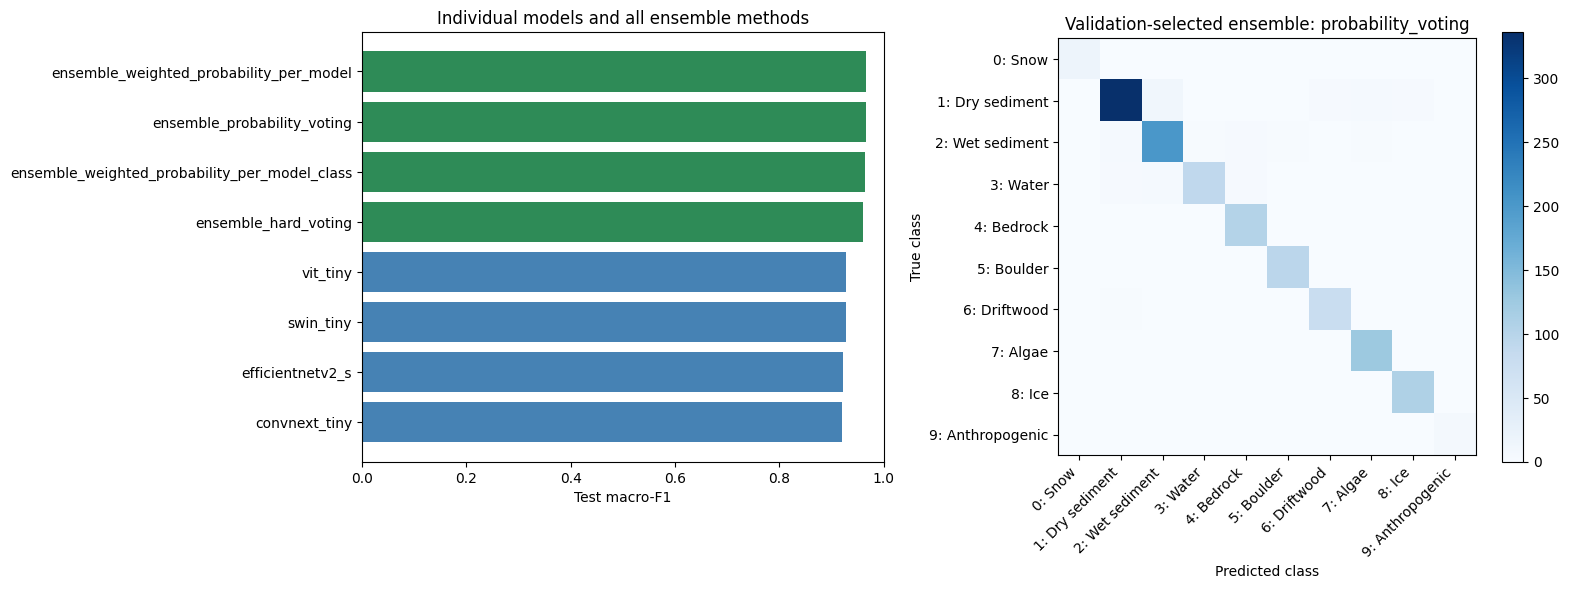

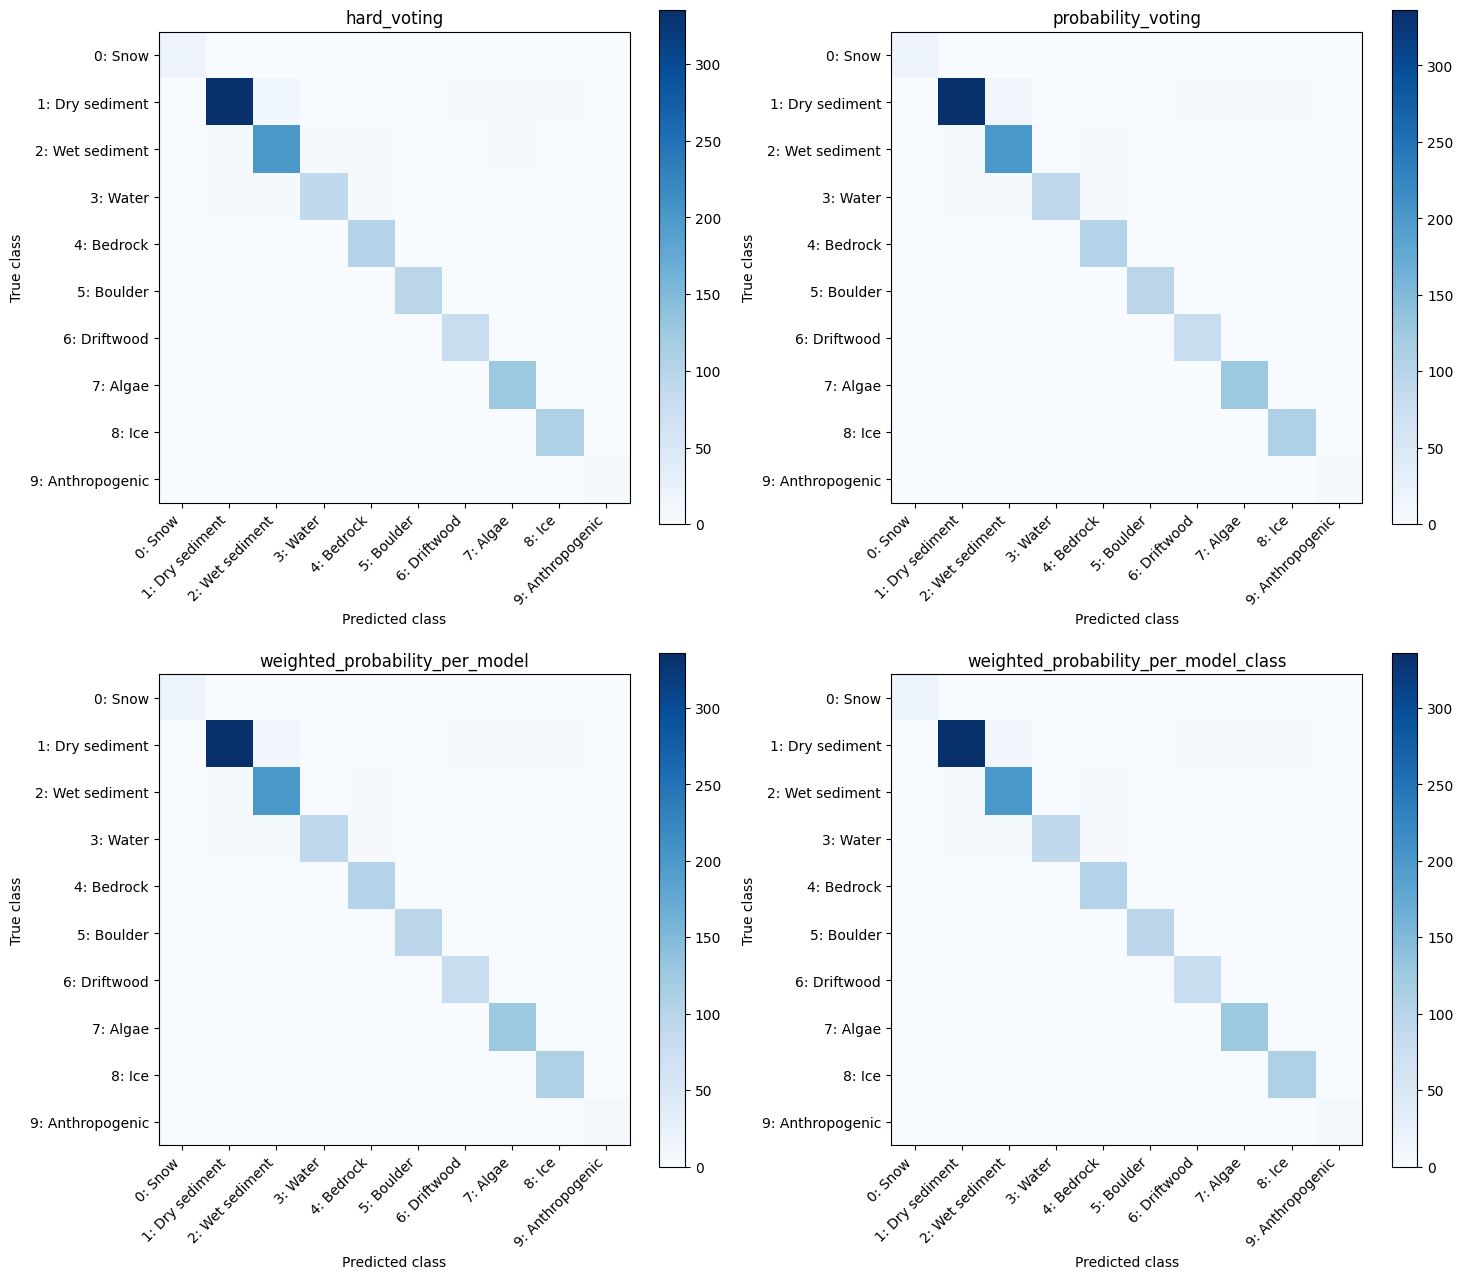

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_comparison = comparison_df.sort_values("macro_f1")
bar_colors = [
    "seagreen" if result_type == "ensemble" else "steelblue"
    for result_type in plot_comparison["result_type"]
]
axes[0].barh(plot_comparison["model"], plot_comparison["macro_f1"], color=bar_colors)
axes[0].set_xlabel("Test macro-F1")
axes[0].set_xlim(0, 1)
axes[0].set_title("Individual models and all ensemble methods")

image = axes[1].imshow(ensemble_confusion.to_numpy(), cmap="Blues")
axes[1].set_xticks(range(len(ensemble_confusion.columns)))
axes[1].set_yticks(range(len(ensemble_confusion.index)))
axes[1].set_xticklabels(ensemble_confusion.columns, rotation=45, ha="right")
axes[1].set_yticklabels(ensemble_confusion.index)
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")
axes[1].set_title(f"Validation-selected ensemble: {best_ensemble_method}")
fig.colorbar(image, ax=axes[1])

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_ensemble_comparison.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, method in zip(axes.flat, ensemble_method_order):
    confusion = test_ensemble_confusions[method]
    image = ax.imshow(confusion.to_numpy(), cmap="Blues")
    ax.set_xticks(range(len(confusion.columns)))
    ax.set_yticks(range(len(confusion.index)))
    ax.set_xticklabels(confusion.columns, rotation=45, ha="right")
    ax.set_yticklabels(confusion.index)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(method)
    fig.colorbar(image, ax=ax)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_all_ensemble_confusion_matrices.png", dpi=150)
plt.show()